# Assignment 3: Soft-Prompt Tuning, Chain of Thought and Critique Fine-Tuning

Foundation of Large Language Models (AI60213), 20 marks.

Read the assignment handout. Complete the designated functions and keep execution outputs. Write a separate report and submit the exported results.json with the notebook and PDF in one ZIP.


In [1]:
import os

os.environ["CUDA_VISIBLE_DEVICES"] = "1"
print(os.environ.get("CUDA_VISIBLE_DEVICES"))

1


In [2]:
import subprocess
import sys
import torch
print("Device:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU (FP32)")
subprocess.run([sys.executable, "-m", "pip", "install", "--quiet",
                "transformers==4.57.1", "accelerate==1.10.1", "datasets==3.6.0",
                "matplotlib", "pandas"], check=True)


Device: NVIDIA L40


CompletedProcess(args=['/home/shivraj-pg/miniconda3/envs/assignment/bin/python', '-m', 'pip', 'install', '--quiet', 'transformers==4.57.1', 'accelerate==1.10.1', 'datasets==3.6.0', 'matplotlib', 'pandas'], returncode=0)

## Utilities and dataset
Download the supplied `assignment3_data.json` and set `DATA_PATH` in the data cell. Use the course file unchanged; no other edits to these supplied cells are needed.

In [3]:
import json
import gc
import hashlib
import math
import random
import re
import time
from contextlib import contextmanager
from decimal import Decimal, InvalidOperation
from itertools import islice
from pathlib import Path
from datetime import datetime, timezone
import pandas as pd
import matplotlib.pyplot as plt
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer

NUMBER_PATTERN = r"[-+]?(?:(?:\d{1,3}(?:,\d{3})+|\d+)(?:\.\d+)?|\.\d+)"
INIT_TEXT = "Solve the arithmetic problem accurately."

TASKS = ("direct", "cot", "critique")
SOLVE_CONDITIONS = ("frozen_direct", "frozen_cot", "tuned_direct", "tuned_cot", "tuned_cft_cot")
CRITIC_CONDITIONS = ("frozen_critic", "tuned_critic")
CRITIQUE_SCORER_VERSION = "2-independent-verdict-and-location"
RESULTS_SCHEMA_VERSION = 3


def configuration():
    return dict(seed=42, model="Qwen/Qwen2.5-0.5B-Instruct",
                model_revision="7ae557604adf67be50417f59c2c2f167def9a775",
                n_train=500, n_val=50, n_test=100, epochs=3,
                virtual_tokens=20, max_seq_length=768, train_batch_size=2,
                gradient_accumulation=8, eval_batch_size=4, learning_rate=3e-3,
                weight_decay=0.0, max_grad_norm=1.0, max_new_tokens=512,
                critic_max_new_tokens=256, do_sample=False, num_beams=1,
                repetition_penalty=1.0, no_repeat_ngram_size=0, device="auto")


def write_json(path, value):
    Path(path).write_text(json.dumps(value, indent=2, ensure_ascii=False, allow_nan=False) + "\n")


def write_jsonl(path, rows):
    Path(path).write_text("".join(json.dumps(row, ensure_ascii=False, allow_nan=False) + "\n" for row in rows))


def load_course_data(payload, cfg):
    """Load balanced splits in source order and check question separation."""
    result = {}
    seen = set()
    for split, key in (("train", "n_train"), ("validation", "n_val"), ("test", "n_test")):
        count = cfg[key]
        if not isinstance(count, int) or count <= 0 or count % 2:
            raise ValueError("Split size must be a positive even integer")
        source = payload["splits"][split]
        rows = []
        for verdict in ("CORRECT", "INCORRECT"):
            rows.extend([e for e in source if e["verdict"] == verdict][:count // 2])
        if len(rows) != count:
            raise ValueError("Requested split exceeds the supplied bank")
        # Preserve the order of the selected records in the supplied dataset.
        ids = {e["source_id"] for e in rows}
        rows = [dict(e) for e in source if e["source_id"] in ids]
        for e in rows:
            if e["question_id"] in seen:
                raise ValueError("A question appears more than once or in multiple splits")
            seen.add(e["question_id"])
        result[split] = rows
    return result


def export_results(path, cfg, results, histories, predictions, pairs):
    if set(predictions) != set(SOLVE_CONDITIONS + CRITIC_CONDITIONS):
        raise ValueError("Export requires all seven conditions")
    expected = None
    for condition, rows in predictions.items():
        ids = {r["source_id"] for r in rows}
        if len(rows) != cfg["n_test"] or len(ids) != len(rows):
            raise ValueError(f"Wrong prediction count or duplicate IDs: {condition}")
        if expected is None:
            expected = ids
        elif ids != expected:
            raise ValueError("Conditions must use the same test question IDs")
    payload = dict(schema_version=RESULTS_SCHEMA_VERSION, critique_scorer_version=CRITIQUE_SCORER_VERSION,
                   configuration=cfg, results=results,
                   histories=histories, predictions=predictions, pairs=pairs)
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    write_json(path, payload)
    return path


def generate_from_embeddings(model, batch, max_new_tokens, pad_id):
    """Return new IDs only for the supplied soft-prompt model."""
    return model.base.generate(**model.prepend(batch["input_ids"], batch["attention_mask"]),
                               do_sample=False, num_beams=1, use_cache=True,
                               max_new_tokens=max_new_tokens, pad_token_id=pad_id)





def numeric_answer(text):
    """Require a final #### number, rather than guessing from intermediate math."""
    if "####" not in text:
        return None
    answer = text.rsplit("####", 1)[-1].strip()
    # Reject fractions, extra prose, and malformed commas instead of accepting
    # their numeric prefix. Accept ordinary decimal GSM8K answer formats.
    if re.fullmatch(NUMBER_PATTERN, answer) is None:
        return None
    try:
        number = Decimal(answer.replace(",", ""))
        return "0" if number == 0 else str(number.normalize())
    except InvalidOperation:
        return None

def display_number(value):
    """Conservative scalar extraction; never consults the reference answer.

    Supports decimal numbers, a short list of units, and English integers 0--99.
    Fractions, expressions, and arbitrary number-bearing prose are rejected.
    """
    value = value.strip().rstrip(".! ").strip()
    # Presentation wrappers around a scalar are not part of its value. Only
    # unwrap a complete number; never evaluate expressions or fractions.
    value = re.sub(r"\\\(\s*(" + NUMBER_PATTERN + r")\s*\\\)", r"\1", value)
    emphasis = re.fullmatch(r"\*\*(.+)\*\*", value)
    if emphasis:
        value = emphasis[1].strip()
    if value.startswith("$"):
        value = value[1:].strip()
    units = (r"(?:dollars?|cents?|years?|days?|weeks?|months?|hours?|minutes?|seconds?|"
             r"inches|inch|feet|foot|pounds?|boxes|apples?|people|degrees?|kg|mm|cm|WPM|%)")
    value = re.sub(r"\s*" + units + r"$", "", value, flags=re.IGNORECASE).strip()
    number = numeric_answer("#### " + value)
    if number is not None:
        return number
    ones = "zero one two three four five six seven eight nine ten eleven twelve thirteen fourteen fifteen sixteen seventeen eighteen nineteen".split()
    tens = {name: 10 * i for i, name in enumerate(
        "zero ten twenty thirty forty fifty sixty seventy eighty ninety".split()) if i >= 2}
    parts = value.lower().replace("-", " ").split()
    if len(parts) == 1 and parts[0] in ones:
        return numeric_answer("#### " + str(ones.index(parts[0])))
    if len(parts) in (1, 2) and parts[0] in tens:
        if len(parts) == 1 or parts[1] in ones[1:10]:
            n = tens[parts[0]] + (ones.index(parts[1]) if len(parts) == 2 else 0)
            return numeric_answer("#### " + str(n))
    return None

def extracted_answer(text, hit_token_limit=False):
    """Diagnostic final-answer heuristic, not a grader of reasoning correctness."""
    strict = numeric_answer(text)
    if strict is not None:
        return strict, "strict"
    if "####" in text:
        tail = text.rsplit("####", 1)[-1].strip()
        line = tail.splitlines()
        if line and re.fullmatch(r"(?:conclusion|final answer|answer|number):?", line[0], re.IGNORECASE):
            # Markdown headings are not numeric answer markers. Only inspect
            # their following content, never an earlier intermediate answer.
            text = "\n".join(line[1:])
        else:
            # A malformed last answer marker must not fall back to an earlier calculation.
            answer = display_number(line[0]) if line else None
            if answer is not None:
                # A valid early marker can be explicitly corrected later. Prefer
                # the later boxed answer, independently of either value's gold.
                later_boxed = re.findall(r"\\boxed\{([^{}]+)\}", tail)
                if later_boxed:
                    final = display_number(later_boxed[-1])
                    return final, "boxed" if final is not None else "none"
            return answer, "marker_line" if answer is not None else "none"
    boxed = re.findall(r"\\boxed\{([^{}]+)\}", text)
    if boxed:
        answer = display_number(boxed[-1])
        return answer, "boxed" if answer is not None else "none"
    # Unmarked unfinished reasoning must not be scored by its last intermediate number.
    if not hit_token_limit:
        final_line = text.strip().splitlines()[-1] if text.strip() else ""
        bold = list(re.finditer(r"\*\*([^*\n]+)\*\*", final_line))
        lines = [line.strip() for line in text.strip().splitlines() if line.strip()]
        heading = (len(lines) >= 2 and re.fullmatch(
            r"#{1,6}\s*(?:conclusion|final answer|answer):?", lines[-2], re.IGNORECASE))
        if (re.match(r"^(?:therefore|thus|so)\b", final_line, re.IGNORECASE) or heading) and len(bold) == 1:
            match = bold[0]
            outside = final_line[:match.start()] + final_line[match.end():]
            # A single emphasized scalar in a final conclusion may have trailing
            # prose. Reject competing values, arithmetic, negation or alternatives.
            if not re.search(r"\d|[=+*/<>]|\b(?:not|or|instead|rather|versus|compare)\b",
                             outside, re.IGNORECASE):
                answer = display_number(match[1])
                if answer is not None:
                    return answer, "bold_conclusion"
        statements = list(re.finditer(r"(?:\bis\b|\bwas\b|\bequals\b|=)\s*", text, re.IGNORECASE))
        for match in reversed(statements):
            answer = display_number(text[match.end():])
            if answer is not None:
                return answer, "final_statement"
        answer = display_number(text)
        if answer is not None:
            return answer, "bare_answer"
    return None, "none"

def score_response(response, reference, hit_token_limit=False):
    strict = numeric_answer(response)
    extracted, method = extracted_answer(response, hit_token_limit)
    return {"prediction": strict, "reference": reference,
            "correct": strict is not None and strict == reference,
            "extracted_prediction": extracted, "extraction_method": method,
            "extracted_correct": extracted is not None and extracted == reference,
            "format_compliant": strict is not None}

def check_scorer_examples():
    """Supplied metric examples; these checks do not assess reasoning quality."""
    cases = [
        ("#### 42", "42", True),
        ("#### 42.", "42", False),
        ("The answer is: 42.", None, False),
        ("Work first.\n#### 42", "42", True),
        ("#### 42\nActually, the correct answer is 41.", "42", False),
        ("Unfinished: 6 times 7", None, False),
    ]
    for response, extracted, compliant in cases:
        scored = score_response(response, "42")
        assert scored["extracted_prediction"] == extracted, response
        assert scored["format_compliant"] == compliant, response
    print(f"Scorer examples: {len(cases)} passed.")

def groups(iterable, size):
    iterator = iter(iterable)
    while batch := list(islice(iterator, size)):
        yield batch


def load_model(cfg):
    requested = cfg.get("device", "auto")
    device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu") if requested == "auto" else torch.device(requested)
    if device.type not in {"cpu", "cuda"}:
        raise ValueError("This loader supports CPU (FP32) and CUDA (FP16); choose device='auto', 'cpu' or 'cuda:0'.")
    if device.type == "cuda" and not torch.cuda.is_available():
        raise RuntimeError("CUDA was requested but is unavailable; select a GPU runtime or set device='cpu'.")
    model = AutoModelForCausalLM.from_pretrained(
        cfg["model"], revision=cfg["model_revision"],
        dtype=torch.float16 if device.type == "cuda" else torch.float32,
        attn_implementation="sdpa",
    ).to(device)
    # inputs_embeds has no prompt token-ID history in the pinned Transformers.
    # Neutralize history-dependent penalties for comparable frozen/tuned decoding.
    model.generation_config.do_sample = cfg["do_sample"]
    model.generation_config.num_beams = cfg["num_beams"]
    model.generation_config.repetition_penalty = cfg["repetition_penalty"]
    model.generation_config.no_repeat_ngram_size = cfg["no_repeat_ngram_size"]
    model.generation_config.temperature = None
    model.generation_config.top_p = None
    model.generation_config.top_k = None
    print("Model device:", device, "base dtype:", next(model.parameters()).dtype)
    return model

def default_output_root():
    """Writable notebook working directory on Kaggle, Colab or a local runtime."""
    root = Path("/kaggle/working") if Path("/kaggle/working").is_dir() else Path.cwd()
    return root / "assignment3"

def eos_ids(model, tokenizer):
    value = model.generation_config.eos_token_id
    if value is None:
        value = tokenizer.eos_token_id
    return set(value if isinstance(value, list) else [value])



/home/shivraj-pg/miniconda3/envs/assignment/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
# Download the supplied course JSON and set its location here.
# Kaggle: attach it as a dataset; Colab: upload it to the session.
DATA_PATH = Path("assignment3_data.json")
DATA_SHA256 = '4ef1b58f05217a72e0343564a9d4b7988ec8646c064f424f959ed956506dc68a'
if not DATA_PATH.is_file():
    raise FileNotFoundError("Download assignment3_data.json and set DATA_PATH to its location.")
if hashlib.sha256(DATA_PATH.read_bytes()).hexdigest() != DATA_SHA256:
    raise ValueError("Use the unchanged assignment3_data.json supplied with this assignment.")
with DATA_PATH.open(encoding="utf-8") as handle:
    COURSE_DATA = json.load(handle)


## Q1. Data pipeline (3 marks)
Implement the functions as specified in the handout.

In [5]:
def prompt_text(tokenizer, example, task):
    """Q1a: format the specified task prompt using allowed input fields only."""
    ## CODE HERE ##
    # raise NotImplementedError('prompt_text')
    
    system_prompt = "You solve arithmetic word problems accurately."
    
    if task=='direct':
        user_prompt = "Give only the final answer in the form #### number."
    elif task=='cot':
        user_prompt = "Show a short step-by-step solution. End with #### number."
    elif task=='critique':
        user_prompt = (
            f"Question:\n{example['question']}\n\n"
            f"Candidate solution:\n{example['candidate']}\n\n"
            "Check the reasoning, not only the final answer. "
            "Use exactly this format:\n"
            "VERDICT: CORRECT or INCORRECT\n"
            "FIRST_ERROR: NONE or a positive step number\n"
            "EXPLANATION: Explain the first error, or state that no error was found."
        )
    else:
        raise ValueError(f"Unknown Task {task} entered")
        
    messages = [
        {"role": "system", "content": system_prompt},
        {"role": "user", "content": user_prompt},
    ]
    
    return tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt = True 
    )

def target_text(example, task):
    """Q1a: construct and validate the direct, CoT or critique target."""
    ## CODE HERE ##
    # raise NotImplementedError('target_text')
    if task == "direct":
        answer = example["answer"]

        if "####" not in answer:
            raise ValueError("Answer is missing the #### final-answer marker.")

        rationale, final = answer.rsplit("####", 1)
        final = final.strip()

        if re.fullmatch(NUMBER_PATTERN, final) is None:
            raise ValueError(f"Invalid final numeric answer: {final}")

        final_answer = f"#### {final}"
        
        return final_answer
    
    elif task == 'cot':
        
        answer = example["answer"]

        if "####" not in answer:
            raise ValueError("Answer is missing the #### final-answer marker.")

        rationale, final = answer.rsplit("####", 1)
        final = final.strip()

        if re.fullmatch(NUMBER_PATTERN, final) is None:
            raise ValueError(f"Invalid final numeric answer: {final}")

        final_answer = f"#### {final}"
        rationale = re.sub(r"<<.*?>>", "", rationale).strip()

        if not rationale:
            raise ValueError("CoT rationale cannot be empty.")

        return rationale + "\n" + final_answer       

    elif task == "critique":
        verdict = example["verdict"]
        first_error = example["first_error"]
        num_steps = example["num_steps"]
        explanation = example["critique"].strip()

        if verdict not in ("CORRECT", "INCORRECT"):
            raise ValueError(f"Invalid verdict: {verdict}")

        if not isinstance(num_steps, int) or num_steps <= 0:
            raise ValueError("num_steps must be a positive integer.")

        if not explanation:
            raise ValueError("Critique explanation cannot be empty.")

        if verdict == "CORRECT":
            if first_error is not None:
                raise ValueError("CORRECT examples must have first_error=None.")
            error_text = "NONE"

        else:
            if (not isinstance(first_error, int)
                    or isinstance(first_error, bool)
                    or not 1 <= first_error <= num_steps):
                raise ValueError("INCORRECT examples require a valid first_error.")
            error_text = str(first_error)

        return (
            f"VERDICT: {verdict}\n"
            f"FIRST_ERROR: {error_text}\n"
            f"EXPLANATION: {explanation}"
        )

    else:
        raise ValueError(f"Unknown task: {task}")

def training_record(tokenizer, example, task):
    """Q1b: construct causal input_ids and response-only labels."""
    ## CODE HERE ##
    # raise NotImplementedError('training_record')
    prefix = tokenizer.encode(
        prompt_text(tokenizer, example, task),
        add_special_tokens=False,
    )

    target = tokenizer.encode(
        target_text(example, task),
        add_special_tokens=False,
    )

    eos_id = tokenizer.eos_token_id

    target = target + [eos_id]

    cfg = configuration()
    max_length = cfg["max_seq_length"]
    virtual_tokens = cfg["virtual_tokens"]

    prefix_budget = max_length - virtual_tokens - len(target)

    if prefix_budget < 0:
        raise ValueError(
            f"Target exceeds maximum sequence length for task {task}."
        )

    if len(prefix) > prefix_budget:
        prefix = prefix[-prefix_budget:] if prefix_budget > 0 else []

    input_ids = prefix + target
    labels = [-100] * len(prefix) + target

    return {
        "input_ids": input_ids,
        "labels": labels,
    }


def collate_training(records, pad_id):
    """Q1c: dynamically right-pad records and mask by position."""
    ## CODE HERE ##
    # raise NotImplementedError('collate_training')
    if not records:
        raise ValueError("Cannot collate an empty batch.")

    max_length = max(len(record["input_ids"]) for record in records)

    input_ids = []
    attention_mask = []
    labels = []

    for record in records:
        ids = record["input_ids"]
        target_labels = record["labels"]

        if len(ids) != len(target_labels):
            raise ValueError("input_ids and labels must have equal lengths.")

        padding_length = max_length - len(ids)

        input_ids.append(ids + [pad_id] * padding_length)
        attention_mask.append([1] * len(ids) + [0] * padding_length)
        labels.append(target_labels + [-100] * padding_length)

    return {
        "input_ids": torch.tensor(input_ids, dtype=torch.long),
        "attention_mask": torch.tensor(attention_mask, dtype=torch.long),
        "labels": torch.tensor(labels, dtype=torch.long),
    }
    
    

## Q2. Input soft prompt (4 marks)
Implement the functions as specified in the handout.

In [6]:
class SoftPromptLM(torch.nn.Module):

    def __init__(self, base, tokenizer, num_tokens=20):
        """Q2a: freeze the base and initialize the independent FP32 input prompt."""
        ## CODE HERE ##
        # raise NotImplementedError('__init__')
        
        super().__init__()

        self.base = base
        self.tokenizer = tokenizer
        self.num_tokens = num_tokens

        if num_tokens <= 0:
            raise ValueError("num_tokens must be positive.")

        for param in self.base.parameters():
            param.requires_grad = False

        embedding_layer = self.base.get_input_embeddings()
        embedding_dim = embedding_layer.weight.shape[1]

        init_ids = tokenizer.encode(INIT_TEXT, add_special_tokens=False)

        if not init_ids:
            raise ValueError("INIT_TEXT produced no tokens.")

        repeated_ids = (init_ids * math.ceil(num_tokens / len(init_ids)))[:num_tokens]

        init_ids_tensor = torch.tensor(
            repeated_ids,
            dtype=torch.long,
            device=embedding_layer.weight.device,
        )

        with torch.no_grad():
            initial_prompt = embedding_layer(init_ids_tensor).detach().float()

        self.prompt = torch.nn.Parameter(initial_prompt.clone())

        assert self.prompt.shape == (num_tokens, embedding_dim)
        assert self.prompt.dtype == torch.float32

    def prepend(self, input_ids, attention_mask, labels=None):
        """Q2b: construct augmented embeddings, masks and optional labels."""
        ## CODE HERE ##
        # raise NotImplementedError('prepend')
        if input_ids.ndim != 2 or attention_mask.shape != input_ids.shape:
            raise ValueError("input_ids and attention_mask must have matching [B, L] shapes.")

        batch_size, seq_length = input_ids.shape

        embedding_layer = self.base.get_input_embeddings()
        input_embeddings = embedding_layer(input_ids)

        prompt_embeddings = self.prompt.unsqueeze(0).expand(batch_size, -1, -1)
        prompt_embeddings = prompt_embeddings.to(dtype=input_embeddings.dtype)

        inputs_embeds = torch.cat([prompt_embeddings, input_embeddings], dim=1,)

        prompt_mask = torch.ones(
            batch_size,
            self.num_tokens,
            dtype=attention_mask.dtype,
            device=attention_mask.device,
        )

        augmented_attention_mask = torch.cat([prompt_mask, attention_mask], dim=1)

        output = {
            "inputs_embeds": inputs_embeds,
            "attention_mask": augmented_attention_mask,
        }

        position_ids = augmented_attention_mask.long().cumsum(dim=-1) - 1
        position_ids.masked_fill_(augmented_attention_mask == 0, 0)
        output["position_ids"] = position_ids

        if labels is not None:
            if labels.shape != input_ids.shape:
                raise ValueError("labels must have the same shape as input_ids.")

            prompt_labels = torch.full(
                (batch_size, self.num_tokens),
                -100,
                dtype=labels.dtype,
                device=labels.device,
            )

            output["labels"] = torch.cat([prompt_labels, labels], dim=1)

        return output

        
        

    def forward(self, input_ids, attention_mask, labels=None):
        """Q2c: return the base output with causal loss and no training cache."""
        ## CODE HERE ##
        # raise NotImplementedError('forward')
        inputs = self.prepend(input_ids, attention_mask, labels)
        return self.base(**inputs, use_cache=False)


## Q3. Training loop (4 marks)
Implement the functions as specified in the handout.

In [7]:
def fit_prompt(model, records, tokenizer, validation, task, cfg, out):
    """Q3: implement token-weighted training, validation and checkpoint saving."""
    ## CODE HERE ##
    # raise NotImplementedError('fit_prompt')

    seed = cfg["seed"]
    random.seed(seed)
    torch.manual_seed(seed)

    device = next(model.base.parameters()).device

    if device.type == "cuda":
        torch.cuda.manual_seed_all(seed)

    generator = torch.Generator()
    generator.manual_seed(seed)

    batch_size = cfg["train_batch_size"]
    accumulation_steps = cfg["gradient_accumulation"]
    epochs = cfg["epochs"]
    max_grad_norm = cfg["max_grad_norm"]

    pad_id = tokenizer.pad_token_id
    if pad_id is None:
        pad_id = tokenizer.eos_token_id

    loader = torch.utils.data.DataLoader(
        records,
        batch_size=batch_size,
        shuffle=True,
        generator=generator,
        collate_fn=lambda rows: collate_training(rows, pad_id),
        drop_last=False,
    )

    optimizer = torch.optim.AdamW(
        [model.prompt],
        lr=cfg["learning_rate"],
        weight_decay=cfg["weight_decay"],
    )

    scaler = (torch.amp.GradScaler("cuda")if device.type == "cuda"else None)

    history = []

    for epoch in range(epochs):

        model.train()
        model.base.eval()

        epoch_loss_sum = 0.0
        epoch_token_count = 0
        max_gradient_norm = 0.0

        optimizer.zero_grad(set_to_none=True)
        window_token_count = 0

        for batch_index, batch in enumerate(loader):

            batch = {key: value.to(device) for key, value in batch.items()}
            supervised_tokens = int((batch["labels"] != -100).sum().item())

            if scaler is not None:
                with torch.autocast(device_type="cuda", dtype=torch.float16):
                    output = model(
                        input_ids=batch["input_ids"],
                        attention_mask=batch["attention_mask"],
                        labels=batch["labels"],
                    )
                    loss = output.loss
            else:
                output = model(
                    input_ids=batch["input_ids"],
                    attention_mask=batch["attention_mask"],
                    labels=batch["labels"],
                )
                loss = output.loss

            if not torch.isfinite(loss):
                raise FloatingPointError("Non-finite training loss.")

            summed_loss = loss * supervised_tokens

            if scaler is not None:
                scaler.scale(summed_loss).backward()
            else:
                summed_loss.backward()

            window_token_count += supervised_tokens

            epoch_loss_sum += loss.detach().float().item() * supervised_tokens
            epoch_token_count += supervised_tokens

            is_window_end = (
                (batch_index + 1) % accumulation_steps == 0
                or (batch_index + 1) == len(loader)
            )

            if is_window_end:

                if scaler is not None:
                    scaler.unscale_(optimizer)

                model.prompt.grad.div_(window_token_count)

                grad_norm = torch.nn.utils.clip_grad_norm_([model.prompt], max_grad_norm)
                max_gradient_norm = max(max_gradient_norm, float(grad_norm.detach().item()))

                if scaler is not None:
                    scaler.step(optimizer)
                    scaler.update()
                else:
                    optimizer.step()

                optimizer.zero_grad(set_to_none=True)
                window_token_count = 0

        response_token_loss = epoch_loss_sum / epoch_token_count

        model.eval()

        with torch.no_grad():
            if task in ("direct", "cot"):
                validation_rows = evaluate_model(model, tokenizer, validation, task, cfg)
                validation_summary = summarize_predictions(validation_rows)

                validation_metric = validation_summary["numeric_accuracy"]
                metric_name = "numeric_accuracy"

            else:
                validation_rows = evaluate_critic(model, tokenizer, validation, cfg)
                validation_summary = summarize_critiques(validation_rows)

                validation_metric = validation_summary["balanced_accuracy"]
                metric_name = "balanced_accuracy"

        epoch_result = {
            "epoch": epoch + 1,
            "response_token_loss": float(response_token_loss),
            "validation_metric": float(validation_metric),
            "validation_metric_name": metric_name,
        }

        history.append(epoch_result)

        print(
            f"{task} | Epoch {epoch + 1}/{epochs} | "
            f"Response-token loss: {response_token_loss:.6f} | "
            f"{metric_name}: {validation_metric:.4f} | "
            f"Max gradient norm: {max_gradient_norm:.4f}"
        )

    print("\nTraining summary")
    print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))
    print("Base model frozen:", all(not p.requires_grad for p in model.base.parameters()))
    print("Base model has no gradients:", all(p.grad is None for p in model.base.parameters()))
    print("Training history:", history)

    if out is not None:
        output_dir = Path(out)
        output_dir.mkdir(parents=True, exist_ok=True)

        torch.save(model.prompt.detach().cpu(), output_dir / f"{task}_prompt.pt")

        write_json(output_dir / f"{task}_history.json", history)

    return history


## Q4. Generation and solving evaluation (2 marks)
Implement the functions as specified in the handout.

In [8]:
def generate_responses(model, tokenizer, examples, task, cfg):
    """Q4a: implement task-aware batched decoding and EOS/token-cap accounting."""
    ## CODE HERE ##
    # raise NotImplementedError('generate_responses')

    device = next((model.base if hasattr(model, "prompt") else model).parameters()).device

    base_model = model.base if hasattr(model, "prompt") else model
    is_soft_prompt = hasattr(model, "prompt")

    if task == "critique":
        max_new_tokens = cfg["critic_max_new_tokens"]
    else:
        max_new_tokens = cfg["max_new_tokens"]

    stop_ids = sorted(eos_ids(base_model, tokenizer))
    eos_id = stop_ids[0] if len(stop_ids) == 1 else stop_ids

    pad_id = tokenizer.pad_token_id
    if pad_id is None:
        pad_id = tokenizer.eos_token_id
        tokenizer.pad_token = tokenizer.eos_token

    base_model.generation_config.eos_token_id = eos_id
    base_model.generation_config.pad_token_id = pad_id
    base_model.generation_config.do_sample = cfg["do_sample"]
    base_model.generation_config.num_beams = cfg["num_beams"]
    base_model.generation_config.repetition_penalty = cfg["repetition_penalty"]
    base_model.generation_config.no_repeat_ngram_size = cfg["no_repeat_ngram_size"]

    old_padding_side = tokenizer.padding_side
    tokenizer.padding_side = "left"

    model.eval()
    results = []

    with torch.no_grad():

        for batch_examples in groups(examples, cfg["eval_batch_size"]):

            prompts = [prompt_text(tokenizer, example, task) for example in batch_examples]

            batch = tokenizer(
                prompts,
                padding=True,
                return_tensors="pt",
                add_special_tokens=False,
            )

            batch = {
                "input_ids": batch["input_ids"].to(device),
                "attention_mask": batch["attention_mask"].to(device),
            }

            if is_soft_prompt:
                generated_ids = generate_from_embeddings(model, batch, max_new_tokens, pad_id)
            else:
                output_ids = model.generate(
                    input_ids=batch["input_ids"],
                    attention_mask=batch["attention_mask"],
                    max_new_tokens=max_new_tokens,
                    do_sample=cfg["do_sample"],
                    num_beams=cfg["num_beams"],
                    repetition_penalty=cfg["repetition_penalty"],
                    no_repeat_ngram_size=cfg["no_repeat_ngram_size"],
                    eos_token_id=eos_id,
                    pad_token_id=pad_id,
                    use_cache=True,
                )

                generated_ids = output_ids[:, batch["input_ids"].shape[1]:]

            for example, token_ids in zip(batch_examples, generated_ids.tolist()):

                eos_position = next((i for i, token_id in enumerate(token_ids) if token_id in stop_ids), None)

                if eos_position is not None:
                    token_ids = token_ids[:eos_position + 1]
                    hit_token_limit = False
                else:
                    hit_token_limit = len(token_ids) >= max_new_tokens

                response = tokenizer.decode(token_ids, skip_special_tokens=True).strip()

                results.append({
                    "source_id": example["source_id"],
                    "question_id": example["question_id"],
                    "question": example["question"],
                    "response": response,
                    "generated_tokens": len(token_ids),
                    "hit_token_limit": hit_token_limit,
                })

    tokenizer.padding_side = old_padding_side

    return results


def evaluate_model(model, tokenizer, examples, task, cfg):
    """Q4a: score solving responses with the supplied number scorer."""
    ## CODE HERE ##
    # raise NotImplementedError('evaluate_model')

    if task not in ("direct", "cot"):
        raise ValueError("evaluate_model supports direct and cot only.")

    predictions = generate_responses(model, tokenizer, examples, task, cfg)

    scored_rows = []

    for example, row in zip(examples, predictions):
        reference = numeric_answer(example["answer"])
        scores = score_response(row["response"], reference, row["hit_token_limit"])
        scored_rows.append({**row, **scores})

    return scored_rows


def summarize_predictions(rows):
    """Q4b: aggregate solving metrics with input validation."""
    ## CODE HERE ##
    # raise NotImplementedError('summarize_predictions')
    if not rows:
        raise ValueError("Prediction rows cannot be empty.")

    ids = [row["source_id"] for row in rows]

    if len(ids) != len(set(ids)):
        raise ValueError("Duplicate source IDs found.")

    n = len(rows)

    numeric_accuracy = sum(row["extracted_correct"] for row in rows)/n
    format_compliance = sum(row["format_compliant"] for row in rows)/n
    unparsed_rate = sum(row["extracted_prediction"] is None for row in rows)/n
    token_limit_rate = sum(row["hit_token_limit"] for row in rows)/n

    return {
        "examples": n,
        "numeric_accuracy": numeric_accuracy,
        "format_compliance": format_compliance,
        "unparsed_rate": unparsed_rate,
        "token_limit_rate": token_limit_rate,
    }


def paired_outcomes(before, after):
    """Q4b: match IDs and compute correctness-transition counts."""
    ## CODE HERE ##
    # raise NotImplementedError('paired_outcomes')

    if not before or not after:
        raise ValueError("Both prediction sets must be non-empty.")

    before_ids = [row["source_id"] for row in before]
    after_ids = [row["source_id"] for row in after]

    if len(before_ids) != len(set(before_ids)):
        raise ValueError("Duplicate IDs in before predictions.")

    if len(after_ids) != len(set(after_ids)):
        raise ValueError("Duplicate IDs in after predictions.")

    before_map = {row["source_id"]: row for row in before}
    after_map = {row["source_id"]: row for row in after}

    if set(before_map) != set(after_map):
        raise ValueError("Before and after prediction IDs do not match.")

    both_correct = 0
    fixed = 0
    broken = 0
    both_wrong = 0

    for source_id in before_map:

        old = before_map[source_id]
        new = after_map[source_id]

        if old["question"] != new["question"]:
            raise ValueError(f"Question mismatch for {source_id}.")

        if old["reference"] != new["reference"]:
            raise ValueError(f"Reference mismatch for {source_id}.")

        old_correct = old["extracted_correct"]
        new_correct = new["extracted_correct"]

        if old_correct and new_correct:
            both_correct += 1
        elif not old_correct and new_correct:
            fixed += 1
        elif old_correct and not new_correct:
            broken += 1
        else:
            both_wrong += 1

    n = len(before)
    before_accuracy = sum(row["extracted_correct"] for row in before)/n
    after_accuracy = sum(row["extracted_correct"] for row in after)/n
    paired_accuracy_change = (fixed - broken) / n

    assert math.isclose(
        after_accuracy - before_accuracy,
        paired_accuracy_change,
        abs_tol=1e-12,
    )

    return {
        "both_correct": both_correct,
        "fixed": fixed,
        "broken": broken,
        "both_wrong": both_wrong,
    }


## Q5. Critique evaluation and transfer (5 marks)
Implement the functions as specified in the handout.

In [9]:
def parse_critique(response, num_steps):
    """Q5a: implement the critique output contract without references; retain field validity independently."""
    ## CODE HERE ##
    # raise NotImplementedError('parse_critique')

    if not isinstance(num_steps, int) or isinstance(num_steps, bool) or num_steps <= 0:
        raise ValueError("num_steps must be a positive integer.")

    text = response.strip()
    lines = text.splitlines()

    header_pattern = re.compile(r"^\s*(VERDICT|FIRST_ERROR|EXPLANATION)\s*:", re.IGNORECASE)

    header_names = [match.group(1).upper() for line in lines if (match := header_pattern.match(line))]

    unique_headers = (
        len(header_names) == 3
        and set(header_names) == {"VERDICT", "FIRST_ERROR", "EXPLANATION"}
        and len(header_names) == len(set(header_names))
    )

    verdict = None

    verdict_matches = [i for i, line in enumerate(lines) if re.match(r"^\s*VERDICT\s*:", line, re.IGNORECASE)]

    if (len(verdict_matches) == 1 and verdict_matches[0] == 0):
        match = re.fullmatch(r"VERDICT:\s*(CORRECT|INCORRECT)\s*", lines[0])
        if match:
            verdict = match.group(1)

    first_error = None
    first_error_valid = False

    error_matches = [i for i, line in enumerate(lines) if re.match(r"^\s*FIRST_ERROR\s*:", line, re.IGNORECASE)]

    if (verdict is not None and len(error_matches) == 1 and error_matches[0] == 1):
        match = re.fullmatch(r"FIRST_ERROR:\s*(NONE|[0-9]+)\s*", lines[1])

        if match:
            value = match.group(1)

            if verdict == "CORRECT" and value == "NONE":
                first_error = None
                first_error_valid = True

            elif verdict == "INCORRECT" and re.fullmatch(r"[1-9][0-9]*", value):
                step = int(value)

                if step <= num_steps:
                    first_error = step
                    first_error_valid = True

    explanation = None
    format_compliant = False

    if (
        len(lines) >= 3
        and verdict is not None
        and first_error_valid
        and unique_headers
        and lines[2].startswith("EXPLANATION:")
        and not any("```" in line for line in lines)
    ):
        explanation_text = lines[2][len("EXPLANATION:"):].strip()

        if len(lines) > 3:
            explanation_text += "\n" + "\n".join(lines[3:]).strip()

        explanation_text = explanation_text.strip()

        if explanation_text:
            explanation = explanation_text
            format_compliant = True

    return {
        "verdict": verdict,
        "first_error": first_error,
        "first_error_valid": first_error_valid,
        "explanation": explanation,
        "format_compliant": format_compliant,
    }


def score_critique(response, num_steps, reference_verdict, reference_first_error):
    """Q5b: validate references and score verdict and first-error agreement."""
    ## CODE HERE ##
    # raise NotImplementedError('score_critique')

    if reference_verdict not in ("CORRECT", "INCORRECT"):
        raise ValueError("Invalid reference verdict.")

    if reference_verdict == "CORRECT":
        if reference_first_error is not None:
            raise ValueError("A CORRECT reference must have first_error=None.")

    else:
        if (
            not isinstance(reference_first_error, int)
            or isinstance(reference_first_error, bool)
            or not 1 <= reference_first_error <= num_steps
        ):
            raise ValueError(
                "An INCORRECT reference must have a valid first-error step."
            )

    parsed = parse_critique(response, num_steps)

    verdict_correct = parsed["verdict"] == reference_verdict

    joint_correct = (verdict_correct and parsed["first_error_valid"] and parsed["first_error"] == reference_first_error)

    return {
        **parsed,
        "reference_verdict": reference_verdict,
        "reference_first_error": reference_first_error,
        "verdict_correct": verdict_correct,
        "joint_correct": joint_correct,
    }


def summarize_critiques(rows):
    """Q5c: compute class recalls, invalid counts and localization metrics."""
    ## CODE HERE ##
    # raise NotImplementedError('summarize_critiques')

    if not rows:
        raise ValueError("Critique rows cannot be empty.")

    ids = [row["source_id"] for row in rows]

    if len(ids) != len(set(ids)):
        raise ValueError("Duplicate source IDs found.")

    correct_rows = [row for row in rows if row["reference_verdict"] == "CORRECT"]
    incorrect_rows = [row for row in rows if row["reference_verdict"] == "INCORRECT"]

    if not correct_rows or not incorrect_rows:
        raise ValueError("Evaluation set must contain both CORRECT and INCORRECT references.")

    n = len(rows)

    def predicted_class(row):
        verdict = row["verdict"]
        return verdict if verdict in ("CORRECT", "INCORRECT") else "INVALID"

    confusion = {
        f"{actual}_{predicted}": 0
        for actual in ("CORRECT", "INCORRECT")
        for predicted in ("CORRECT", "INCORRECT", "INVALID")
    }

    for row in rows:
        actual = row["reference_verdict"]
        predicted = predicted_class(row)
        confusion[f"{actual}_{predicted}"] += 1

    correct_recall = confusion["CORRECT_CORRECT"]/len(correct_rows)
    incorrect_recall = confusion["INCORRECT_INCORRECT"]/len(incorrect_rows)
    verdict_accuracy = sum(row["verdict_correct"] for row in rows)/n
    balanced_accuracy = (correct_recall + incorrect_recall)/2
    false_rejection_rate = sum(row["verdict"]=="INCORRECT" for row in correct_rows)/len(correct_rows)
    correct_invalid_rate = sum(row["verdict"] is None for row in correct_rows)/len(correct_rows)
    first_error_accuracy = sum(row["joint_correct"] for row in incorrect_rows)/len(incorrect_rows)
    joint_accuracy = sum(row["joint_correct"] for row in rows)/n
    format_compliance = sum(row["format_compliant"] for row in rows)/n
    token_limit_rate = sum(row["hit_token_limit"] for row in rows)/n

    return {
        "examples": n,
        "verdict_accuracy": verdict_accuracy,
        "balanced_accuracy": balanced_accuracy,
        "correct_recall": correct_recall,
        "incorrect_recall": incorrect_recall,
        "false_rejection_rate": false_rejection_rate,
        "correct_invalid_rate": correct_invalid_rate,
        "first_error_accuracy": first_error_accuracy,
        "joint_accuracy": joint_accuracy,
        "format_compliance": format_compliance,
        "token_limit_rate": token_limit_rate,
        "confusion": confusion,
    }


def evaluate_critic(model, tokenizer, examples, cfg):
    """Q5d: generate critiques, then attach references and scores."""
    ## CODE HERE ##
    # raise NotImplementedError('evaluate_critic')

    predictions = generate_responses(model, tokenizer, examples, "critique", cfg)
    scored_rows = []
    for example, row in zip(examples, predictions):

        scores = score_critique(
            row["response"],
            example["num_steps"],
            example["verdict"],
            example["first_error"],
        )

        scored_rows.append({
            **row,
            "candidate": example["candidate"],
            "num_steps": example["num_steps"],
            "reference_explanation": example["critique"],
            **scores,
        })

    return scored_rows


def run_study(cfg, tokenizer, payload, out):
    """Q5e: independently train three prompts and evaluate seven conditions."""
    ## CODE HERE ##
    # raise NotImplementedError('run_study')

    splits = load_course_data(payload, cfg)

    train_data = splits["train"]
    validation = splits["validation"]
    test_data = splits["test"]

    print("Configuration:")
    print(json.dumps(cfg, indent=2))

    print("\nSplit sizes:")
    print({
        "train": len(train_data),
        "validation": len(validation),
        "test": len(test_data),
    })


    train_records = {
        task: [
            training_record(tokenizer, example, task)
            for example in train_data
        ]
        for task in TASKS
    }

    for task in TASKS:
        if len(train_records[task]) != len(train_data):
            raise ValueError(f"Missing training records for {task}.")

        for record in train_records[task]:
            total_length = len(record["input_ids"]) + cfg["virtual_tokens"]
            

            if total_length > cfg["max_seq_length"]:
                raise ValueError(
                    f"{task} record exceeds max_seq_length: "
                    f"{total_length} tokens. No truncation is applied."
                )

    base = load_model(cfg)
    model = SoftPromptLM(base, tokenizer, num_tokens=cfg["virtual_tokens"])

    initial_prompt = model.prompt.detach().clone()

    histories = {}
    learned_prompts = {}

    for task in TASKS:
        print(f"\n{'=' * 20} Training {task} {'=' * 20}")
        
        with torch.no_grad():
            model.prompt.copy_(initial_prompt)

        task_out = Path(out) / "training" if out is not None else None

        histories[task] = fit_prompt(
            model=model,
            records=train_records[task],
            tokenizer=tokenizer,
            validation=validation,
            task=task,
            cfg=cfg,
            out=task_out,
        )

        learned_prompts[task] = model.prompt.detach().cpu().clone()

    predictions = {}

    print("\nEvaluating frozen solving conditions...")

    predictions["frozen_direct"] = evaluate_model(base, tokenizer, test_data, "direct", cfg)
    predictions["frozen_cot"] = evaluate_model(base, tokenizer, test_data, "cot", cfg)

    with torch.no_grad():
        model.prompt.copy_(learned_prompts["direct"].to(model.prompt.device))

    predictions["tuned_direct"] = evaluate_model(model, tokenizer, test_data, "direct", cfg)

    with torch.no_grad():
        model.prompt.copy_(learned_prompts["cot"].to(model.prompt.device))

    predictions["tuned_cot"] = evaluate_model(model, tokenizer, test_data, "cot", cfg)

    with torch.no_grad():
        model.prompt.copy_(learned_prompts["critique"].to(model.prompt.device))

    predictions["tuned_cft_cot"] = evaluate_model(model, tokenizer, test_data, "cot", cfg)

    print("\nEvaluating frozen critic...")

    predictions["frozen_critic"] = evaluate_critic(base, tokenizer, test_data, cfg)

    with torch.no_grad():
        model.prompt.copy_(learned_prompts["critique"].to(model.prompt.device))

    predictions["tuned_critic"] = evaluate_critic(model, tokenizer, test_data, cfg)

    results = {"solving": [], "critique": []}

    for condition in SOLVE_CONDITIONS:
        summary = summarize_predictions(predictions[condition])
        results["solving"].append({
            "condition": condition,
            **summary,
        })

    for condition in CRITIC_CONDITIONS:
        summary = summarize_critiques(predictions[condition])
        results["critique"].append({
            "condition": condition,
            **summary,
        })

    pairs = {
        "direct": paired_outcomes(
            predictions["frozen_direct"],
            predictions["tuned_direct"],
        ),
        "cot": paired_outcomes(
            predictions["frozen_cot"],
            predictions["tuned_cot"],
        ),
        "cft_transfer": paired_outcomes(
            predictions["frozen_cot"],
            predictions["tuned_cft_cot"],
        ),
    }

    print("\nTraining histories:")
    for task, history in histories.items():
        print(f"\n{task}:")
        print(history)

    print("\nSolving results:")
    print(pd.DataFrame(results["solving"]).to_string(index=False))

    print("\nCritique results:")
    print(pd.DataFrame(results["critique"]).to_string(index=False))

    print("\nPaired outcomes:")
    print(json.dumps(pairs, indent=2))

    return results, histories, predictions, pairs


## Q6. Figures and analysis (2 marks)
Implement the functions as specified in the handout.

In [10]:
def make_figures(results, histories, pairs, out):
    """Q6a: save/display the required tables and separate metric plots."""
    ## CODE HERE ##
    # raise NotImplementedError('make_figures')


    out = Path(out)
    out.mkdir(parents=True, exist_ok=True)

    solving_table = pd.DataFrame(results["solving"])
    critique_table = pd.DataFrame(results["critique"])
    paired_table = pd.DataFrame.from_dict(pairs, orient="index")
    paired_table.index.name = "comparison"
    paired_table = paired_table.reset_index()

    solving_table.to_csv(out / "solving_results.csv", index=False)
    critique_table.to_csv(out / "critique_results.csv", index=False)
    paired_table.to_csv(out / "paired_outcomes.csv", index=False)

    print("Solving results:")
    display(solving_table)

    print("Critique results:")
    display(critique_table)

    print("Paired outcomes:")
    display(paired_table)

    confusion_rows = []
    for row in results["critique"]:
        confusion = row["confusion"]
        confusion_rows.append({
            "condition": row["condition"],
            **confusion
        })

    confusion_table = pd.DataFrame(confusion_rows)
    print("Critique confusion counts:")
    display(confusion_table)

    confusion_table.to_csv(out / "critique_confusion.csv", index=False)

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))

    for ax, task in zip(axes, ("direct", "cot", "critique")):
        history = histories[task]
        epochs = [item["epoch"] for item in history]
        losses = [item["response_token_loss"] for item in history]

        ax.plot(epochs, losses, marker="o")
        ax.set_title(f"{task.upper()} training loss")
        ax.set_xlabel("Epoch")
        ax.set_ylabel("Response-token loss")
        ax.set_xticks(epochs)
        ax.grid(True, alpha=0.3)

    fig.tight_layout()
    fig.savefig(out / "training_loss.png", dpi=200, bbox_inches="tight")
    plt.show()

    fig, ax = plt.subplots(figsize=(7, 5))

    for task in ("direct", "cot"):
        history = histories[task]
        epochs = [item["epoch"] for item in history]
        metrics = [item["validation_metric"] for item in history]

        ax.plot(epochs, metrics, marker="o", label=task.upper())

    ax.set_title("Solving validation accuracy")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Numeric accuracy")
    ax.set_xticks(epochs)
    ax.legend()
    ax.grid(True, alpha=0.3)

    fig.tight_layout()
    fig.savefig(out / "solving_validation_accuracy.png",
                dpi=200, bbox_inches="tight")
    plt.show()

    history = histories["critique"]
    epochs = [item["epoch"] for item in history]
    metrics = [item["validation_metric"] for item in history]

    fig, ax = plt.subplots(figsize=(7, 5))
    ax.plot(epochs, metrics, marker="o")

    ax.set_title("Critique validation balanced accuracy")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Balanced accuracy")
    ax.set_xticks(epochs)
    ax.grid(True, alpha=0.3)

    fig.tight_layout()
    fig.savefig(out / "critique_validation_accuracy.png",
                dpi=200, bbox_inches="tight")
    plt.show()

    return solving_table, critique_table, paired_table
    

## Implementation checks
Demonstrate masking/padding, trainable counts, prompt updates, frozen base weights and critique metric edge cases.

In [11]:
# Add the required checks here.


## Training configuration and execution

Scorer examples: 6 passed.
Chosen configuration: {
  "seed": 42,
  "model": "Qwen/Qwen2.5-0.5B-Instruct",
  "model_revision": "7ae557604adf67be50417f59c2c2f167def9a775",
  "n_train": 500,
  "n_val": 50,
  "n_test": 100,
  "epochs": 3,
  "virtual_tokens": 20,
  "max_seq_length": 768,
  "train_batch_size": 2,
  "gradient_accumulation": 8,
  "eval_batch_size": 4,
  "learning_rate": 0.003,
  "weight_decay": 0.0,
  "max_grad_norm": 1.0,
  "max_new_tokens": 512,
  "critic_max_new_tokens": 256,
  "do_sample": false,
  "num_beams": 1,
  "repetition_penalty": 1.0,
  "no_repeat_ngram_size": 0,
  "device": "auto",
  "data_sha256": "4ef1b58f05217a72e0343564a9d4b7988ec8646c064f424f959ed956506dc68a"
}
Configuration:
{
  "seed": 42,
  "model": "Qwen/Qwen2.5-0.5B-Instruct",
  "model_revision": "7ae557604adf67be50417f59c2c2f167def9a775",
  "n_train": 500,
  "n_val": 50,
  "n_test": 100,
  "epochs": 3,
  "virtual_tokens": 20,
  "max_seq_length": 768,
  "train_batch_size": 2,
  "gradient_accumulation": 8

W1102 18:04:51.646000 604328 site-packages/torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1102 18:04:51.671000 604328 site-packages/torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


Model device: cuda:0 base dtype: torch.float16

==================== Training direct ====================
direct | Epoch 1/3 | Response-token loss: 1.328967 | numeric_accuracy: 0.0200 | Max gradient norm: 57.3541
direct | Epoch 2/3 | Response-token loss: 1.097801 | numeric_accuracy: 0.0200 | Max gradient norm: 4.1429
direct | Epoch 3/3 | Response-token loss: 1.085345 | numeric_accuracy: 0.0000 | Max gradient norm: 3.3044

Training summary
Trainable parameters: 17920
Base model frozen: True
Base model has no gradients: True
Training history: [{'epoch': 1, 'response_token_loss': 1.328966925245746, 'validation_metric': 0.02, 'validation_metric_name': 'numeric_accuracy'}, {'epoch': 2, 'response_token_loss': 1.0978009353212441, 'validation_metric': 0.02, 'validation_metric_name': 'numeric_accuracy'}, {'epoch': 3, 'response_token_loss': 1.0853446746519544, 'validation_metric': 0.0, 'validation_metric_name': 'numeric_accuracy'}]

==================== Training cot ====================
cot | Ep

,condition,examples,numeric_accuracy,format_compliance,unparsed_rate,token_limit_rate
0,frozen_direct,100,0.00,0.0,1.0,0.0
1,frozen_cot,100,0.00,0.0,1.0,0.0
2,tuned_direct,100,0.01,1.0,0.0,0.0
3,tuned_cot,100,0.00,0.0,1.0,1.0
4,tuned_cft_cot,100,0.00,0.0,1.0,0.0


Critique results:


,condition,examples,verdict_accuracy,balanced_accuracy,correct_recall,incorrect_recall,false_rejection_rate,correct_invalid_rate,first_error_accuracy,joint_accuracy,format_compliance,token_limit_rate,confusion
0,frozen_critic,100,0.5,0.5,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,"{'CORRECT_CORRECT': 50, 'CORRECT_INCORRECT': 0..."
1,tuned_critic,100,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.61,"{'CORRECT_CORRECT': 0, 'CORRECT_INCORRECT': 0,..."


Paired outcomes:


,comparison,both_correct,fixed,broken,both_wrong
0,direct,0,1,0,99
1,cot,0,0,0,100
2,cft_transfer,0,0,0,100


Critique confusion counts:


,condition,CORRECT_CORRECT,CORRECT_INCORRECT,CORRECT_INVALID,INCORRECT_CORRECT,INCORRECT_INCORRECT,INCORRECT_INVALID
0,frozen_critic,50,0,0,50,0,0
1,tuned_critic,0,0,50,0,0,50


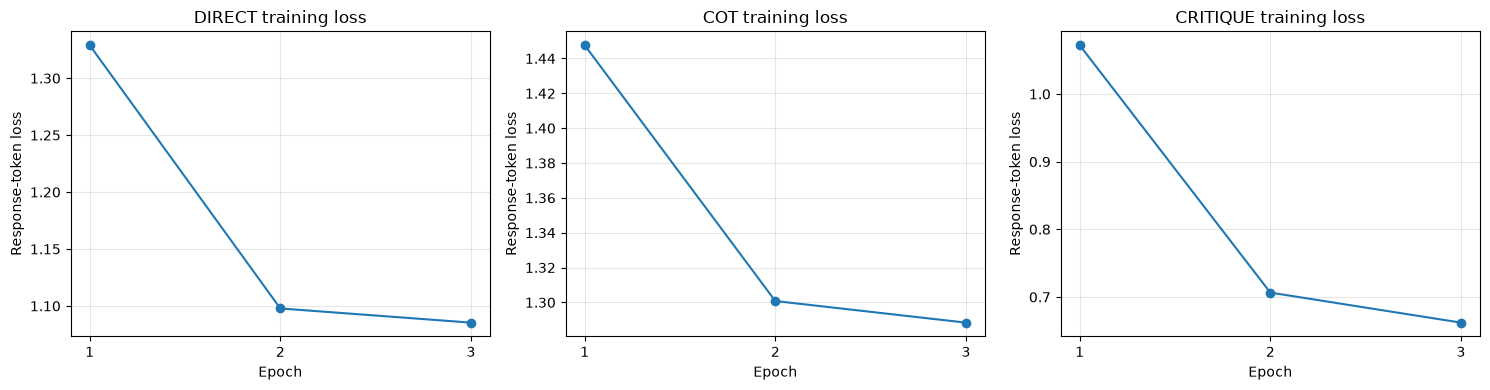

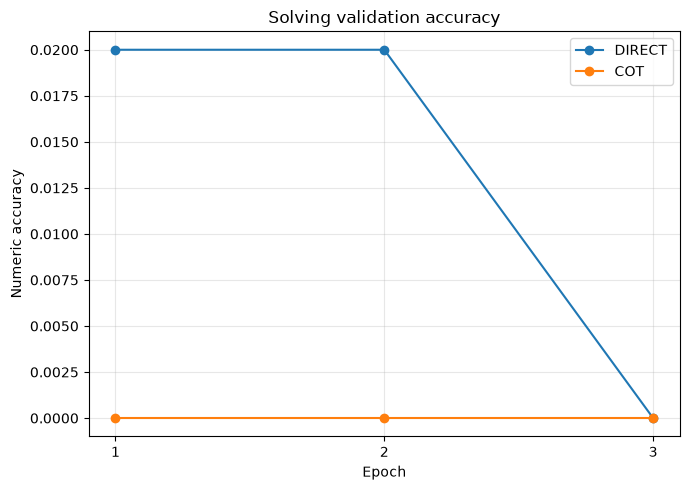

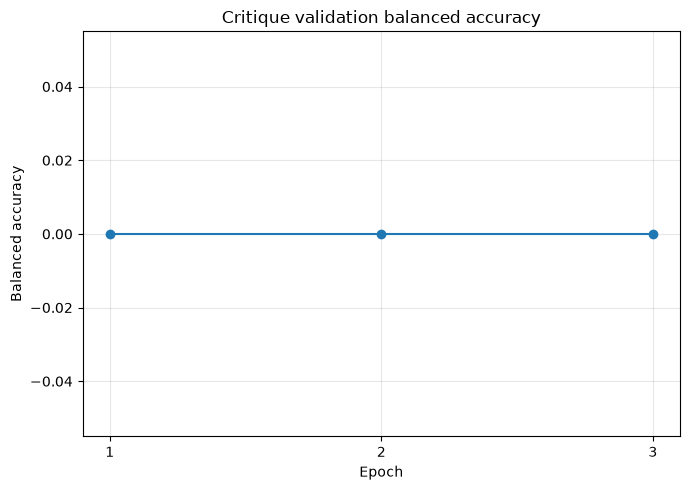

In [12]:
check_scorer_examples()
cfg = configuration()
# Recommended starting settings. Explain any changes to training defaults.
cfg.update(epochs=3, learning_rate=0.003, train_batch_size=2,
           gradient_accumulation=8, eval_batch_size=4)
cfg["data_sha256"] = DATA_SHA256
print("Chosen configuration:", json.dumps(cfg, indent=2))
tokenizer = AutoTokenizer.from_pretrained(cfg["model"], revision=cfg["model_revision"])
if tokenizer.pad_token_id is None:
    tokenizer.pad_token = tokenizer.eos_token
stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
output_root = Path("/kaggle/working") if Path("/kaggle/working").is_dir() else Path.cwd()
out = output_root / "assignment3_cft" / f"run_{stamp}"
results, histories, predictions, pairs = run_study(cfg, tokenizer, COURSE_DATA, out)
tables = make_figures(results, histories, pairs, out)


## Response analysis
Display the five questions, references, candidates and all seven responses required by Q6. Present the full response analyses here; summarize their findings in the separate report without repeating all raw responses.

In [15]:
# Select and display the five examples specified in Q6.

# Select and display the five examples specified in Q6.

import pandas as pd

test_examples = COURSE_DATA["splits"]["test"]

correct_examples = [e for e in test_examples if e["verdict"] == "CORRECT"]
incorrect_examples = [e for e in test_examples if e["verdict"] == "INCORRECT" and e["candidate_answer_correct"] is False]

correct_answer_wrong_reasoning = [e for e in test_examples if e["verdict"] == "INCORRECT" and e["candidate_answer_correct"] is True]

selected_examples = correct_examples[:2] + incorrect_examples[:2] + correct_answer_wrong_reasoning[:1]

if len(selected_examples) != 5:
    raise ValueError("Could not select five examples with the required categories.")

prediction_lookup = {
    condition: {
        row["source_id"]: row
        for row in rows
    }
    for condition, rows in predictions.items()
}

conditions = [
    "frozen_direct",
    "frozen_cot",
    "tuned_direct",
    "tuned_cot",
    "tuned_cft_cot",
    "frozen_critic",
    "tuned_critic",
]

for i, example in enumerate(selected_examples, 1):

    source_id = example["source_id"]

    print(f"\n{'=' * 100}")
    print(f"EXAMPLE {i}: {example['question_id']}")
    print(f"{'=' * 100}")

    metadata = pd.DataFrame([{
        "question_id": example["question_id"],
        "source_id": source_id,
        "question": example["question"],
        "reference_answer": example["answer"],
        "reference_verdict": example["verdict"],
        "reference_first_error": example["first_error"],
        "reference_critique": example["critique"],
        "candidate_solution": example["candidate"],
        "candidate_answer_correct": example["candidate_answer_correct"],
    }])

    display(metadata.T.rename(columns={0: "Value"}))

    response_rows = []

    for condition in conditions:
        if condition not in prediction_lookup:
            raise ValueError(f"Missing prediction condition: {condition}")

        if source_id not in prediction_lookup[condition]:
            raise ValueError(f"Missing prediction for {source_id} in {condition}")

        response_rows.append({
            "condition": condition,
            "raw_response": prediction_lookup[condition][source_id]["response"],
        })

    display(pd.DataFrame(response_rows))


EXAMPLE 1: gsm8k:test:1136


,Value
question_id,gsm8k:test:1136
source_id,mr:8c2506ed-84e6-4916-8f0c-c32a98613d00
question,Bob has a certain number of marbles. If he rec...
reference_answer,Let B be the number of marbles Bob starts with...
reference_verdict,CORRECT
reference_first_error,None
reference_critique,No incorrect step is identified in the candida...
candidate_solution,Step 1: We know that Bob has a certain number ...
candidate_answer_correct,True


,condition,raw_response
0,frozen_direct,"Sure, please provide the arithmetic word probl..."
1,frozen_cot,"Sure, let's solve the arithmetic word problem ..."
2,tuned_direct,#### 120
3,tuned_cot,The total number of students in the number of ...
4,tuned_cft_cot,You solve arithmetic word problems accurately....
5,frozen_critic,VERDICT: CORRECT\nFIRST_ERROR: No error was fo...
6,tuned_critic,VERDIE: INCORIGINATEX\nCORRECT\nVERDICT\nCORRE...



EXAMPLE 2: gsm8k:test:998


,Value
question_id,gsm8k:test:998
source_id,mr:671ac935-4d52-4184-9f32-d18ae1088ecf
question,Dylan attended a wedding where there were 100 ...
reference_answer,If each of the 100 guests brought a plate of 1...
reference_verdict,CORRECT
reference_first_error,None
reference_critique,No incorrect step is identified in the candida...
candidate_solution,Step 1: There were 100 guests at the wedding a...
candidate_answer_correct,True


,condition,raw_response
0,frozen_direct,"Sure, please provide the arithmetic word probl..."
1,frozen_cot,"Sure, let's solve the arithmetic word problem ..."
2,tuned_direct,#### 120
3,tuned_cot,The total number of students in the number of ...
4,tuned_cft_cot,You solve arithmetic word problems accurately....
5,frozen_critic,VERDICT: CORRECT\nFIRST_ERROR: No error was fo...
6,tuned_critic,VERDylan attended the wedding had 1\nVERCIR\nV...


... (5 outputs left out)

,condition,raw_response
0,frozen_direct,"Sure, please provide the arithmetic word probl..."
1,frozen_cot,"Sure, let's solve the arithmetic word problem ..."
2,tuned_direct,#### 120
3,tuned_cot,The total number of students in the number of ...
4,tuned_cft_cot,You solve arithmetic word problems accurately....
5,frozen_critic,VERDICT: CORRECT\nFIRST_ERROR: No error was fo...
6,tuned_critic,VERDIE: INCORIGINATEX\nVERDICTURECTRY: INCOR N...



EXAMPLE 5: gsm8k:test:210


,Value
question_id,gsm8k:test:210
source_id,mr:cb12c615-8b9a-4a04-acd5-59113113d1df
question,Sara wants to buy herself a new jacket and 2 p...
reference_answer,Both pairs of shoes will cost a total of 2 * $...
reference_verdict,INCORRECT
reference_first_error,3
reference_critique,"The description is incorrect, it should say th..."
candidate_solution,Step 1: The cost of the jacket is $30.\nStep 2...
candidate_answer_correct,True


,condition,raw_response
0,frozen_direct,"Sure, please provide the arithmetic word probl..."
1,frozen_cot,"Sure, let's solve the arithmetic word problem ..."
2,tuned_direct,#### 120
3,tuned_cot,The total number of students in the number of ...
4,tuned_cft_cot,You solve arithmetic word problems accurately....
5,frozen_critic,VERDICT: CORRECT\nFIRST_ERROR: No error was fo...
6,tuned_critic,VERDIE: INCOR NONE\nDUESTILL\nVERDID: NONE\nVE...


## Export results
Include `results.json` with your executed notebook and PDF report in your submission ZIP. It must contain one prediction for each of the 100 test questions under each of the seven evaluation conditions (700 records in total).

In [16]:
path = export_results(out / "results.json", cfg, results, histories, predictions, pairs)
print("Exported", sum(map(len, predictions.values())), "prediction records to", path)


Exported 700 prediction records to /home/shivraj-pg/Assign3/assignment3_cft/run_20261102T180450_959162Z/results.json


In [ ]:
total_records = sum(len(rows) for rows in predictions.values())

print("Total prediction records:", total_records)
print("Evaluation conditions:", len(predictions))

for condition, rows in predictions.items():
    unique_ids = {row["source_id"] for row in rows}

    print(
        f"{condition}: {len(rows)} records, "
        f"{len(unique_ids)} unique test questions"
    )

    assert len(rows) == 100, f"{condition} does not have 100 records."
    assert len(unique_ids) == 100, f"{condition} has duplicate source IDs."

assert len(predictions) == 7, "Expected exactly seven evaluation conditions."
assert total_records == 700, f"Expected 700 records, got {total_records}."

print("\nSUCCESS: All seven conditions have 100 unique predictions each.")

Total prediction records: 700
Evaluation conditions: 7
frozen_direct: 100 records, 100 unique test questions
frozen_cot: 100 records, 100 unique test questions
tuned_direct: 100 records, 100 unique test questions
tuned_cot: 100 records, 100 unique test questions
tuned_cft_cot: 100 records, 100 unique test questions
frozen_critic: 100 records, 100 unique test questions
tuned_critic: 100 records, 100 unique test questions

SUCCESS: All seven conditions have 100 unique predictions each.
